In [1]:
# pmdarima를 임포트하기 위한 설치

# Install Condacolab to integrate Conda with Colab
!pip install -q condacolab

# Import and run Condacolab to enable Conda
import condacolab
condacolab.install()

# Install pmdarima from conda-forge using Conda
!conda install -c conda-forge pmdarima -y

⏬ Downloading https://github.com/jaimergp/miniforge/releases/download/24.11.2-1_colab/Miniforge3-colab-24.11.2-1_colab-Linux-x86_64.sh...
📦 Installing...
📌 Adjusting configuration...
🩹 Patching environment...
⏲ Done in 0:00:35
🔁 Restarting kernel...
Channels:
 - conda-forge
Platform: linux-64
Solving environment: / - \ done

## Package Plan ##

  environment location: /usr/local

  added / updated specs:
    - pmdarima


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    ca-certificates-2025.4.26  |       hbd8a1cb_0         149 KB  conda-forge
    certifi-2025.1.31          |     pyhd8ed1ab_0         159 KB  conda-forge
    conda-24.11.3              |  py311h38be061_0         1.1 MB  conda-forge
    cython-3.0.12              |  py311ha3e34f5_0         3.6 MB  conda-forge
    joblib-1.4.2               |     pyhd8ed1ab_1         215 KB  conda-forge
    libblas-3.9.0              |31_

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import warnings
warnings.filterwarnings("ignore")

In [3]:
# 한글 깨짐 방지 위해 구글 코랩에 나눔폰트 설치.
import sys
if 'google.colab' in sys.modules:
    !echo 'debconf debconf/frontend select Noninteractive' | debconf-set-selections
    !sudo apt-get -qq -y install fonts-nanum
    import matplotlib.font_manager as fm
    font_files = fm.findSystemFonts(fontpaths=['/usr/share/fonts/truetype/nanum'])
    for fpath in font_files:
        fm.fontManager.addfont(fpath)

Selecting previously unselected package fonts-nanum.
(Reading database ... 126101 files and directories currently installed.)
Preparing to unpack .../fonts-nanum_20200506-1_all.deb ...
Unpacking fonts-nanum (20200506-1) ...
Setting up fonts-nanum (20200506-1) ...
Processing triggers for fontconfig (2.13.1-4.2ubuntu5) ...


# 필요한 라이브러리

In [4]:
# 필요한 라이브러리 설치 및 임포트
import pandas as pd
import datetime
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, ExponentialSmoothing
from statsmodels.graphics.tsaplots import plot_acf,plot_pacf
from statsmodels.tsa.ar_model import AutoReg,ARResults
from pmdarima import auto_arima
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from sklearn.metrics import mean_squared_error as mse
from sklearn.metrics import r2_score

In [5]:
plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

# 필요한 함수

In [6]:
# 퓨리에 변환으로 주기를 파악하는 함수
def find_period_to_FFT(data, graph=True):
    signal = data.dropna()  # 이산 신호

    # 퓨리에 변환
    N = len(signal) # 샘플 개수
    dt = 3600  # 1시간 단위 = 3600초  1시간단위로 샘플링
    fft_result = np.fft.fft(signal) # DTFT
    freqs = np.fft.fftfreq(N, d=dt) # 주파수 벡터 생성
    amplitude = np.abs(fft_result) # 진폭을 보기 위해 절댓값을 취함.

    # 양의 주파수만 추출
    mask = freqs > 0
    positive_freqs = freqs[mask]
    positive_amplitude = amplitude[mask]

    # 상위 주파수 성분 추출
    N_top = 10
    top_idx = np.argsort(positive_amplitude)[-N_top:]
    dominant_freqs = positive_freqs[top_idx]
    dominant_amplitudes = positive_amplitude[top_idx]

    # 주기 계산
    dominant_periods_sec = 1 / dominant_freqs
    dominant_periods_hours = dominant_periods_sec / 3600
    dominant_periods_days = dominant_periods_hours / 24


    dominant_df = pd.DataFrame({
        'Frequency (Hz)': dominant_freqs,
        'Amplitude': dominant_amplitudes,
        'Period (hours)': dominant_periods_hours,
        'Period (days)': dominant_periods_days
    })

    # 진폭 기준으로 내림차순 정렬
    dominant_df = dominant_df.sort_values(by='Amplitude', ascending=False)

    # 결과 출력
    print("주요 주기 성분 (상위 {}개, 진폭 기준 정렬):".format(N_top))
    for idx, row in dominant_df.iterrows():
        print(f"- 주파수: {row['Frequency (Hz)']:.6f} Hz | 진폭: {row['Amplitude']:.2f} | 주기: {row['Period (hours)']:.2f} 시간 ≈ {row['Period (days)']:.2f} 일")

    # 스펙트럼 시각화
    if graph:
        threshold = positive_amplitude.max() * 0.2
        mask = positive_amplitude > threshold

        plt.figure(figsize=(15, 5))
        plt.plot((positive_freqs[mask]) * 3600, positive_amplitude[mask])  # 주파수를 1/hour 단위로
        plt.plot(dominant_freqs * 3600, dominant_amplitudes, 'o', color='red', label='Top Frequencies', markersize=4)
        plt.title(f'{data.name} - 퓨리에 변환 결과')
        plt.xlabel('Frequency (1/hour)')
        plt.ylabel('Amplitude')
        plt.grid(True)
        plt.show()

In [7]:
from statsmodels.tsa.stattools import adfuller
# 디키-풀러 테스트 함수(정상성 확인 함수) - 추세 존재 여부 확인
def adf_test(series,title=''):
    """
    Pass in a time series and an optional title, returns an ADF report
    """
    print(f'Augmented Dickey-Fuller Test: {title}')
    result = adfuller(series.dropna(),autolag='AIC') # .dropna() handles differenced data

    labels = ['ADF test statistic','p-value','# lags used','# observations']
    out = pd.Series(result[0:4],index=labels)

    for key,val in result[4].items():
        out[f'critical value ({key})']=val

    print(out.to_string())          # .to_string() removes the line "dtype: float64"

    if result[1] <= 0.05:
        print("Strong evidence against the null hypothesis")
        print("Reject the null hypothesis")
        print("Data has no unit root and is stationary")
    else:
        print("Weak evidence against the null hypothesis")
        print("Fail to reject the null hypothesis")
        print("Data has a unit root and is non-stationary")

# [1] 데이터 셋 불러오기

In [8]:
df_21 = pd.read_csv('/content/drive/MyDrive/AI+X/AI+X선도인재양성프로젝트(중급)/(제공용) 미세먼지 교안, 데이터 및 실습 과제/df_21.csv', index_col='time', parse_dates=True)
df_22 = pd.read_csv('/content/drive/MyDrive/AI+X/AI+X선도인재양성프로젝트(중급)/(제공용) 미세먼지 교안, 데이터 및 실습 과제/df_22.csv', index_col='time', parse_dates=True)

In [9]:
df_21.head(3)

,지역,SO2,CO,O3,NO2,PM10,PM25,기온(°C),강수량(mm),풍속(m/s),...,3시간신적설(cm),전운량(10분위),중하층운량(10분위),최저운고(100m ),시정(10m),지면온도(°C),5cm 지중온도(°C),10cm 지중온도(°C),20cm 지중온도(°C),30cm 지중온도(°C)
time,,,,,,,,,,,,,,,,,,,,,
2021-01-01 01:00:00,서울 종로구,0.002,0.5,0.022,0.016,24.0,14.0,-8.7,0.0,2.4,...,0.0,0.0,0,999.0,2000,-6.9,-1.0,-0.8,0.3,1.6
2021-01-01 02:00:00,서울 종로구,0.002,0.6,0.018,0.020,25.0,14.0,-9.1,0.0,1.6,...,0.0,0.0,0,999.0,2000,-7.1,-1.1,-0.8,0.3,1.6
2021-01-01 03:00:00,서울 종로구,0.002,0.6,0.013,0.025,27.0,16.0,-9.3,0.0,1.1,...,0.0,0.0,0,999.0,2000,-7.3,-1.2,-0.9,0.3,1.6


In [10]:
df_22.head(3)

,지역,SO2,CO,O3,NO2,PM10,PM25,기온(°C),강수량(mm),풍속(m/s),...,3시간신적설(cm),전운량(10분위),중하층운량(10분위),최저운고(100m ),시정(10m),지면온도(°C),5cm 지중온도(°C),10cm 지중온도(°C),20cm 지중온도(°C),30cm 지중온도(°C)
time,,,,,,,,,,,,,,,,,,,,,
2022-01-01 00:00:00,서울 종로구,0.003,0.4,0.026,0.016,20.0,9.0,-8.5,0.0,1.9,...,0.0,0,0,999.0,2000,-7.0,-1.0,-1.0,-0.2,1.0
2022-01-01 01:00:00,서울 종로구,0.003,0.4,0.026,0.016,23.0,12.0,-9.2,0.0,1.8,...,0.0,0,0,999.0,2000,-7.2,-1.1,-1.1,-0.2,1.0
2022-01-01 02:00:00,서울 종로구,0.003,0.4,0.022,0.020,20.0,9.0,-9.5,0.0,1.2,...,0.0,0,0,999.0,2000,-7.5,-1.3,-1.2,-0.2,1.0


In [11]:
df_21.index.freq = 'h'

In [12]:
df_22.index.freq = 'h'

# [2] 미세먼지 데이터만 추출

In [13]:
pm10_2021 = df_21['PM10']
pm10_2022 = df_22['PM10']

In [14]:
pm10_2021.head()

,PM10
time,
2021-01-01 01:00:00,24.0
2021-01-01 02:00:00,25.0
2021-01-01 03:00:00,27.0
2021-01-01 04:00:00,23.0
2021-01-01 05:00:00,24.0


In [15]:
pm10_2022.head()

,PM10
time,
2022-01-01 00:00:00,20.0
2022-01-01 01:00:00,23.0
2022-01-01 02:00:00,20.0
2022-01-01 03:00:00,20.0
2022-01-01 04:00:00,19.0


## 2-1. 미세먼지 데이터셋 만들기

In [16]:
pm10_2021_df = pd.DataFrame()
pm10_2021_df['PM10'] = pm10_2021

In [17]:
pm10_2021_df.index.freq = 'h'

# [3] 시계열 분석

## 3-1. 시각화로 전체적인 동향 파악

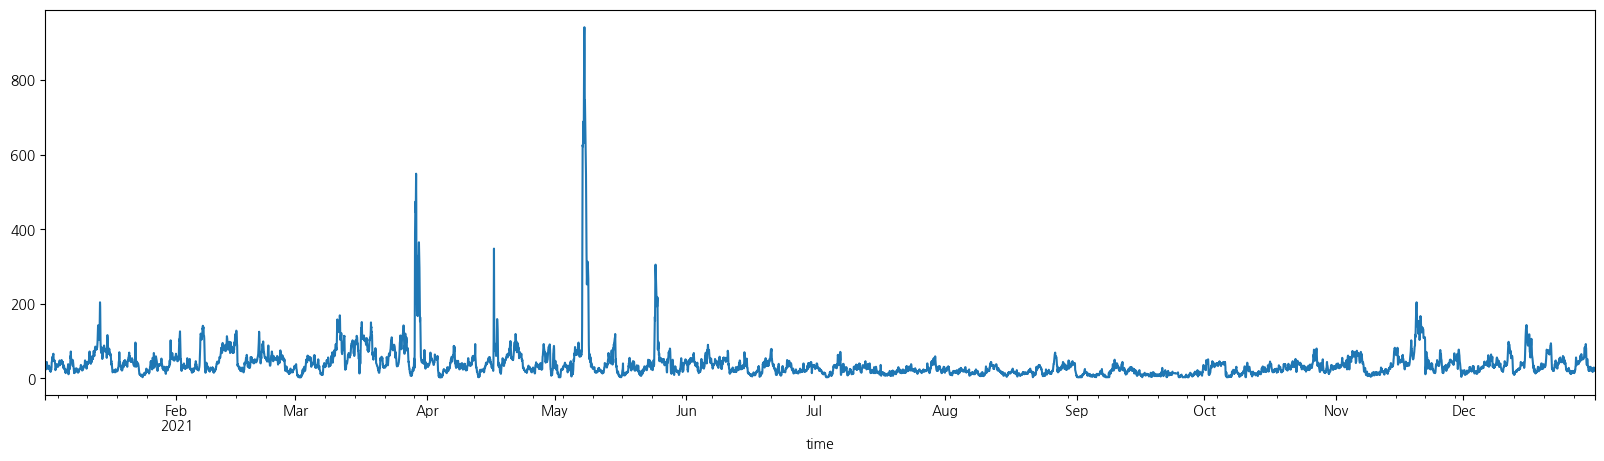

In [18]:
pm10_2021.plot(figsize=(20, 5));

## 3-2. 퓨리에 변환을 통한 주기 파악

주요 주기 성분 (상위 10개, 진폭 기준 정렬):
- 주파수: 0.000000 Hz | 진폭: 86664.33 | 주기: 8759.00 시간 ≈ 364.96 일
- 주파수: 0.000001 Hz | 진폭: 44304.68 | 주기: 437.95 시간 ≈ 18.25 일
- 주파수: 0.000001 Hz | 진폭: 40905.44 | 주기: 336.88 시간 ≈ 14.04 일
- 주파수: 0.000002 Hz | 진폭: 40493.27 | 주기: 182.48 시간 ≈ 7.60 일
- 주파수: 0.000001 Hz | 진폭: 39537.38 | 주기: 461.00 시간 ≈ 19.21 일
- 주파수: 0.000000 Hz | 진폭: 35181.78 | 주기: 673.77 시간 ≈ 28.07 일
- 주파수: 0.000001 Hz | 진폭: 34312.20 | 주기: 224.59 시간 ≈ 9.36 일
- 주파수: 0.000000 Hz | 진폭: 34069.42 | 주기: 4379.50 시간 ≈ 182.48 일
- 주파수: 0.000002 Hz | 진폭: 33711.84 | 주기: 153.67 시간 ≈ 6.40 일
- 주파수: 0.000000 Hz | 진폭: 32742.99 | 주기: 973.22 시간 ≈ 40.55 일


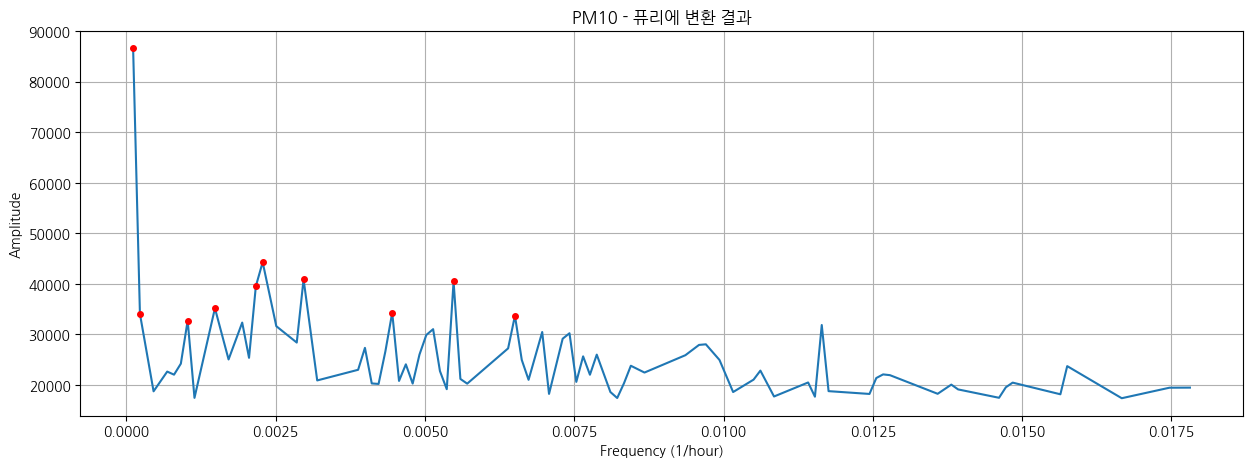

In [19]:
find_period_to_FFT(pm10_2021)

## 3-3. 추세, 계절성, 잔차 파악

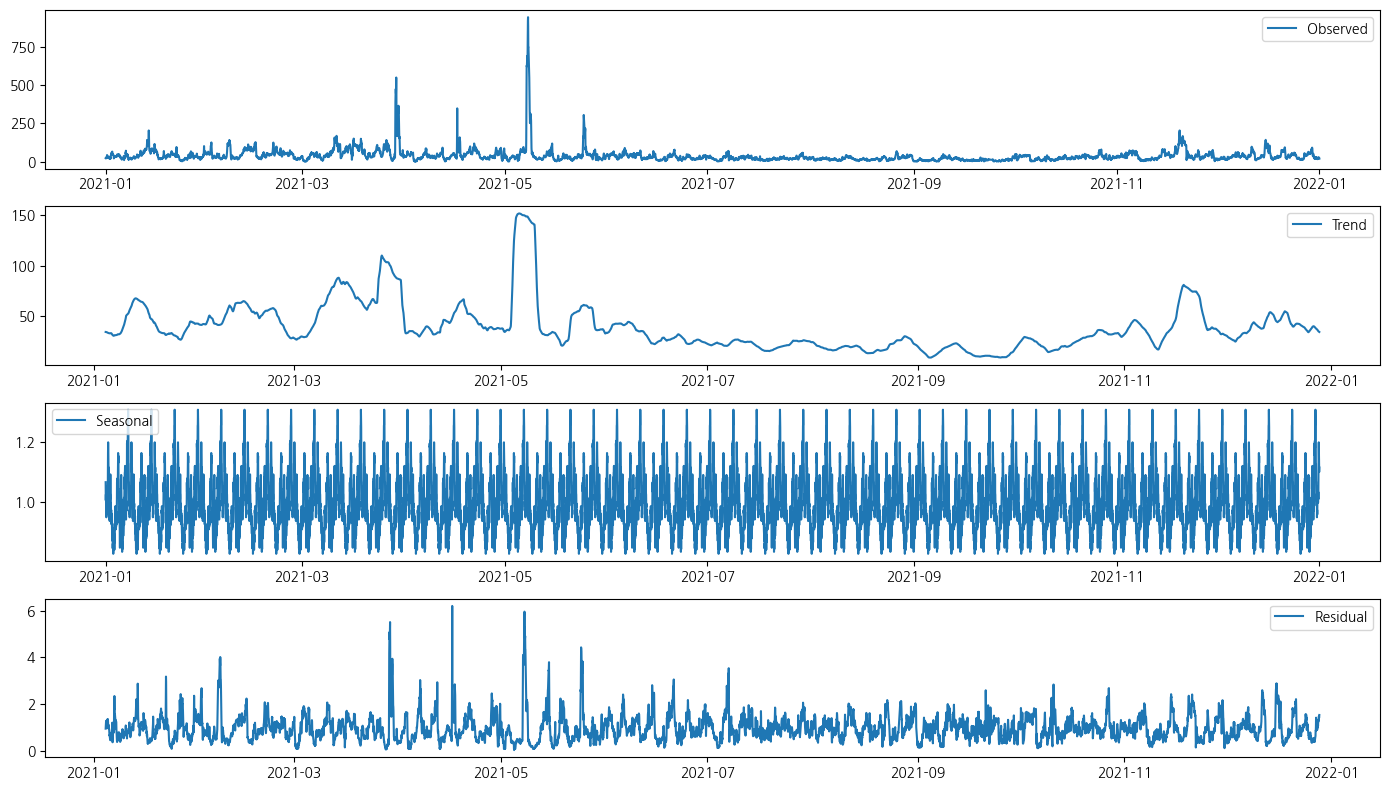

In [20]:
day = 7
result = seasonal_decompose(pm10_2021, model='multiplicative', period=24*day)

observed = result.observed
trend = result.trend
seasonal = result.seasonal
resid = result.resid

plt.figure(figsize=(14, 8))

plt.subplot(411)
plt.plot(observed, label='Observed')
plt.legend()

plt.subplot(412)
plt.plot(trend, label='Trend')
plt.legend()

plt.subplot(413)
plt.plot(seasonal, label='Seasonal')
plt.legend()

plt.subplot(414)
plt.plot(resid, label='Residual')
plt.legend()

plt.tight_layout()
plt.show()

## 3-4. SMA

In [21]:
pm10_2021_df['7-day-SMA'] = pm10_2021_df['PM10'].rolling(window=7*24).mean()
pm10_2021_df['28-day-SMA'] = pm10_2021_df['PM10'].rolling(window=28*24).mean()

In [22]:
pm10_2021_df['7-day-SMA']

,7-day-SMA
time,
2021-01-01 01:00:00,NaN
2021-01-01 02:00:00,NaN
2021-01-01 03:00:00,NaN
2021-01-01 04:00:00,NaN
2021-01-01 05:00:00,NaN
...,...
2021-12-31 19:00:00,34.910714
2021-12-31 20:00:00,34.791667
2021-12-31 21:00:00,34.666667


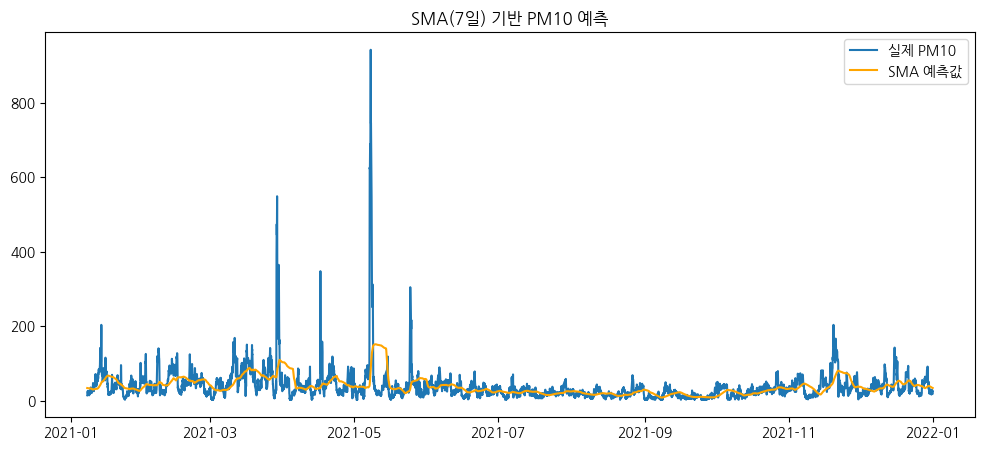

In [23]:
pm10_2021_df['7-day-SMA_Predict'] = pm10_2021_df['7-day-SMA'].shift(1)

# 3. 실제값과 예측값 비교 (NaN 제거)
result = pm10_2021_df[['PM10', '7-day-SMA_Predict']].dropna()

# 4. 예측 시각화
plt.figure(figsize=(12, 5))
plt.plot(result['PM10'], label='실제 PM10')
plt.plot(result['7-day-SMA_Predict'], label='SMA 예측값', color='orange')
plt.title('SMA(7일) 기반 PM10 예측')
plt.legend()
plt.show()

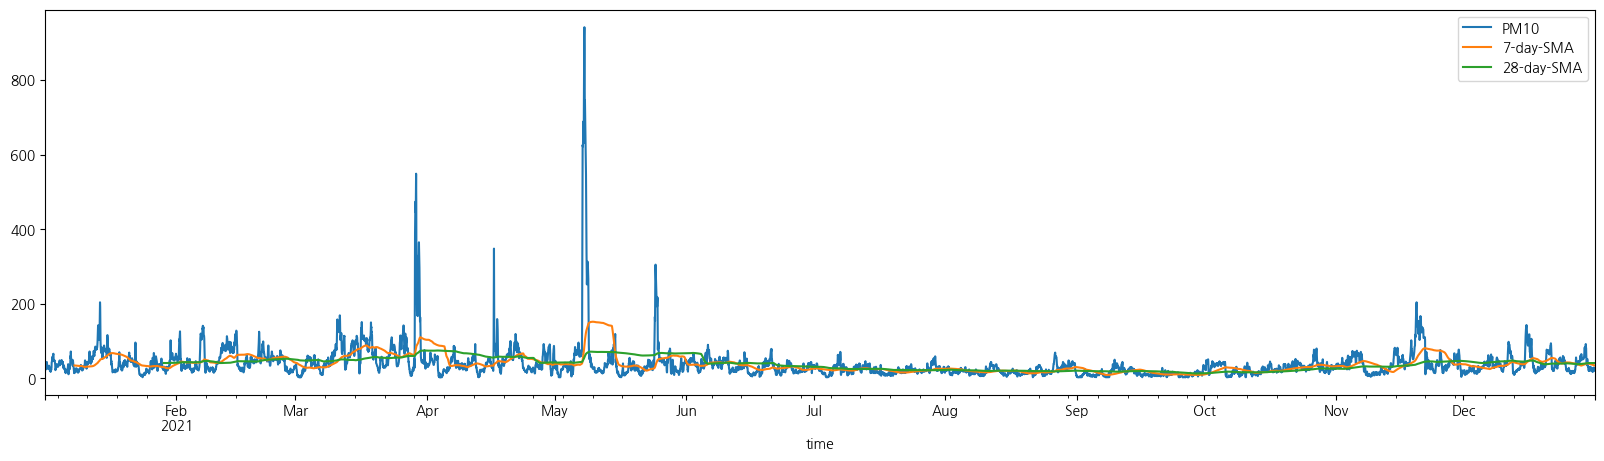

In [24]:
pm10_2021_df[['PM10','7-day-SMA', '28-day-SMA']].plot(figsize=(20, 5)).autoscale(axis='x',tight=True);

## 3-5. EWMA

In [25]:
pm10_2021_df['7-day-EWMA'] = pm10_2021_df['PM10'].ewm(span=7*24,adjust=False).mean()
pm10_2021_df['28-day-EWMA'] = pm10_2021_df['PM10'].ewm(span=28*24,adjust=False).mean()

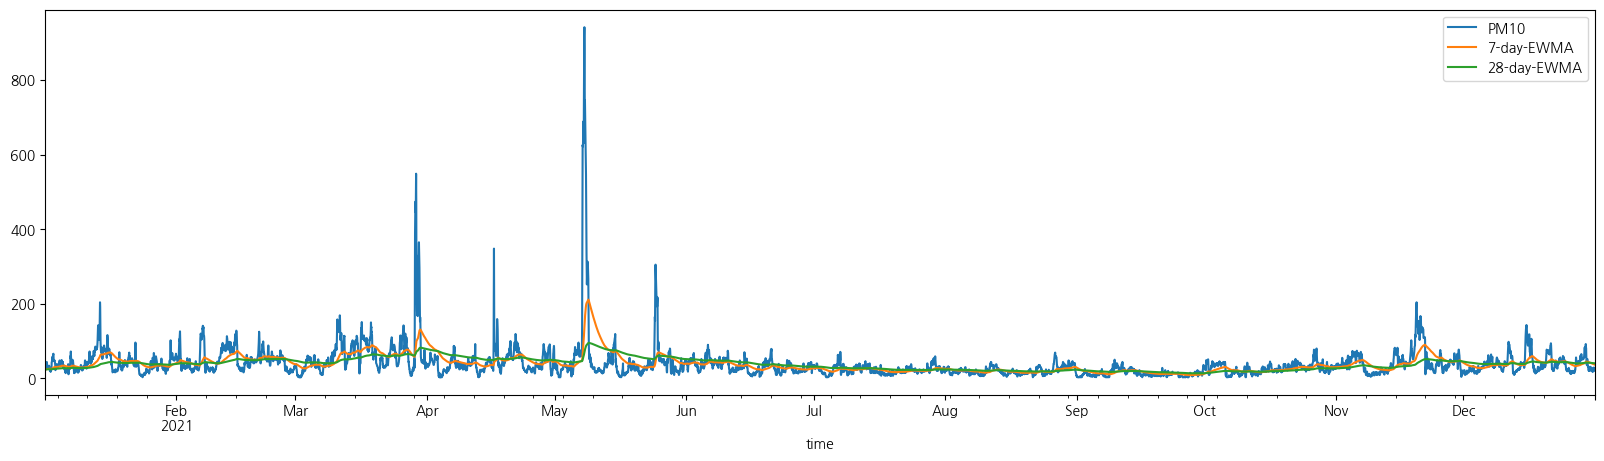

In [26]:
pm10_2021_df[['PM10', '7-day-EWMA', '28-day-EWMA']].plot(figsize=(20, 5)).autoscale(axis='x',tight=True);

## 3-6. 지수 평활법

### 3-6-1. 단순 지수 평활법

In [27]:
span = 6  # 주기 지정
alpha = 2/(span+1)

pm10_2021_df['7-day-SES']=SimpleExpSmoothing(pm10_2021_df['PM10']).fit(smoothing_level=alpha,optimized=False).fittedvalues.shift(-1) # 7-day-EWMA와 같은 값이 나옴.
pm10_2021_df.head()

,PM10,7-day-SMA,28-day-SMA,7-day-SMA_Predict,7-day-EWMA,28-day-EWMA,7-day-SES
time,,,,,,,
2021-01-01 01:00:00,24.0,NaN,NaN,NaN,24.000000,24.000000,24.000000
2021-01-01 02:00:00,25.0,NaN,NaN,NaN,24.011834,24.002972,24.285714
2021-01-01 03:00:00,27.0,NaN,NaN,NaN,24.047197,24.011878,25.061224
2021-01-01 04:00:00,23.0,NaN,NaN,NaN,24.034804,24.008871,24.472303
2021-01-01 05:00:00,24.0,NaN,NaN,NaN,24.034392,24.008845,24.337359


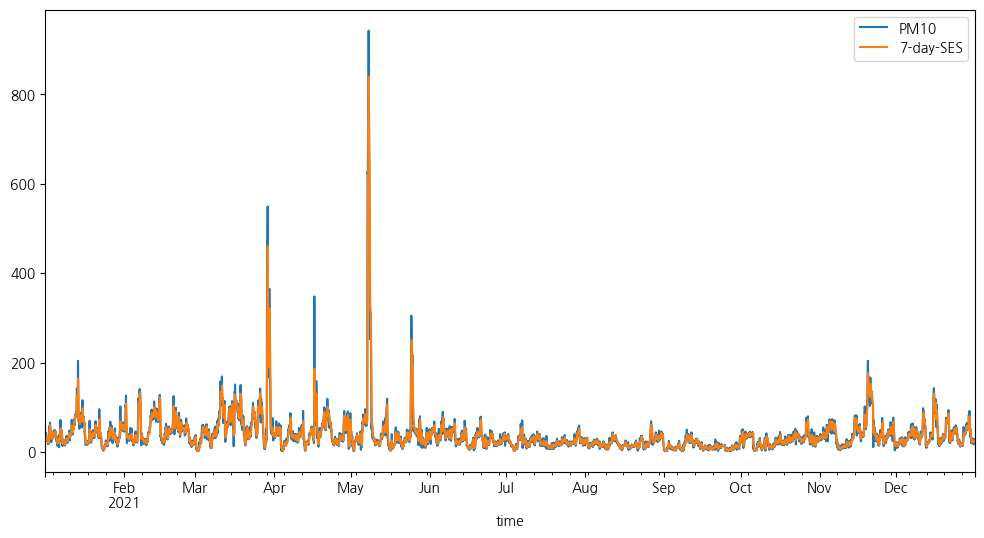

In [28]:
pm10_2021_df[['PM10', '7-day-SES']].plot(figsize=(12,6)).autoscale(axis='x',tight=True);

In [29]:
model = SimpleExpSmoothing(pm10_2021_df['PM10']).fit(smoothing_level=alpha, optimized=False)

forecast_1 = model.forecast(steps=6) # steps시간 만큼 예측
forecast_1

,0
2022-01-01 00:00:00,22.837165
2022-01-01 01:00:00,22.837165
2022-01-01 02:00:00,22.837165
2022-01-01 03:00:00,22.837165
2022-01-01 04:00:00,22.837165
2022-01-01 05:00:00,22.837165


In [30]:
df_22['PM10'].head(6)

,PM10
time,
2022-01-01 00:00:00,20.0
2022-01-01 01:00:00,23.0
2022-01-01 02:00:00,20.0
2022-01-01 03:00:00,20.0
2022-01-01 04:00:00,19.0
2022-01-01 05:00:00,24.0


In [31]:
print(np.sqrt(mse(forecast_1.values, df_22['PM10'].head(6).values)))

2.590078774726602


In [32]:
r2_score(df_22['PM10'].head(6).values, forecast_1.values)

-1.012552417786777

### 3-6-2. 이중 지수 평활법

In [33]:
pm10_2021_df['DES(add)'] = ExponentialSmoothing(pm10_2021_df['PM10'], trend='add').fit().fittedvalues.shift(-1) # mul로 했더니 오버플로우 발생 + 파라미터(알파, 베타 등)를 찾기 위한 최적화 과정이 수렴하지 못했다는 경고가 뜸.
pm10_2021_df.head()

,PM10,7-day-SMA,28-day-SMA,7-day-SMA_Predict,7-day-EWMA,28-day-EWMA,7-day-SES,DES(add)
time,,,,,,,,
2021-01-01 01:00:00,24.0,NaN,NaN,NaN,24.000000,24.000000,24.000000,25.526643
2021-01-01 02:00:00,25.0,NaN,NaN,NaN,24.011834,24.002972,24.285714,26.400812
2021-01-01 03:00:00,27.0,NaN,NaN,NaN,24.047197,24.011878,25.061224,28.550548
2021-01-01 04:00:00,23.0,NaN,NaN,NaN,24.034804,24.008871,24.472303,23.142082
2021-01-01 05:00:00,24.0,NaN,NaN,NaN,24.034392,24.008845,24.337359,24.332492


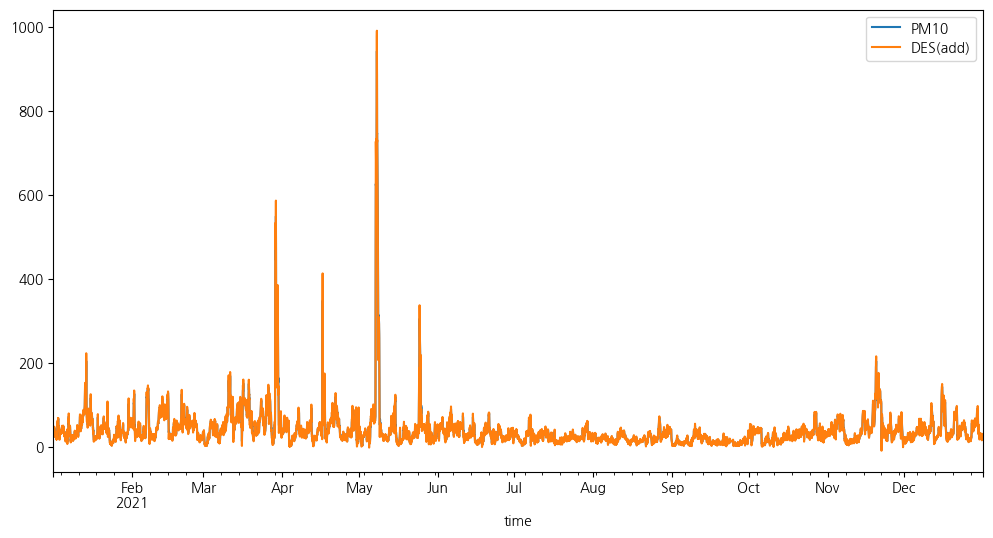

In [34]:
pm10_2021_df[['PM10', 'DES(add)']].plot(figsize=(12,6)).autoscale(axis='x',tight=True);

In [35]:
model = ExponentialSmoothing(pm10_2021_df['PM10'], trend='add').fit()

forecast_2 = model.forecast(steps=6) # steps시간 만큼 예측
forecast_2

,0
2022-01-01 00:00:00,18.945439
2022-01-01 01:00:00,17.897696
2022-01-01 02:00:00,16.849953
2022-01-01 03:00:00,15.802210
2022-01-01 04:00:00,14.754467
2022-01-01 05:00:00,13.706724


In [36]:
print(np.sqrt(mse(forecast_2.values, df_22['PM10'].head(6).values)))

5.456890540073545


In [37]:
r2_score(df_22['PM10'].head(6).values, forecast_2.values)

-7.933296309903241

### 3-6-3. 삼중 지수 평활법(Holt-Winters)

In [38]:
pm10_2021_df['7-day-TES(add)'] = ExponentialSmoothing(pm10_2021_df['PM10'],trend='add',seasonal='add',seasonal_periods=7*24).fit().fittedvalues
pm10_2021_df.head()

,PM10,7-day-SMA,28-day-SMA,7-day-SMA_Predict,7-day-EWMA,28-day-EWMA,7-day-SES,DES(add),7-day-TES(add)
time,,,,,,,,,
2021-01-01 01:00:00,24.0,NaN,NaN,NaN,24.000000,24.000000,24.000000,25.526643,32.923881
2021-01-01 02:00:00,25.0,NaN,NaN,NaN,24.011834,24.002972,24.285714,26.400812,22.739972
2021-01-01 03:00:00,27.0,NaN,NaN,NaN,24.047197,24.011878,25.061224,28.550548,26.391078
2021-01-01 04:00:00,23.0,NaN,NaN,NaN,24.034804,24.008871,24.472303,23.142082,26.597714
2021-01-01 05:00:00,24.0,NaN,NaN,NaN,24.034392,24.008845,24.337359,24.332492,26.079675


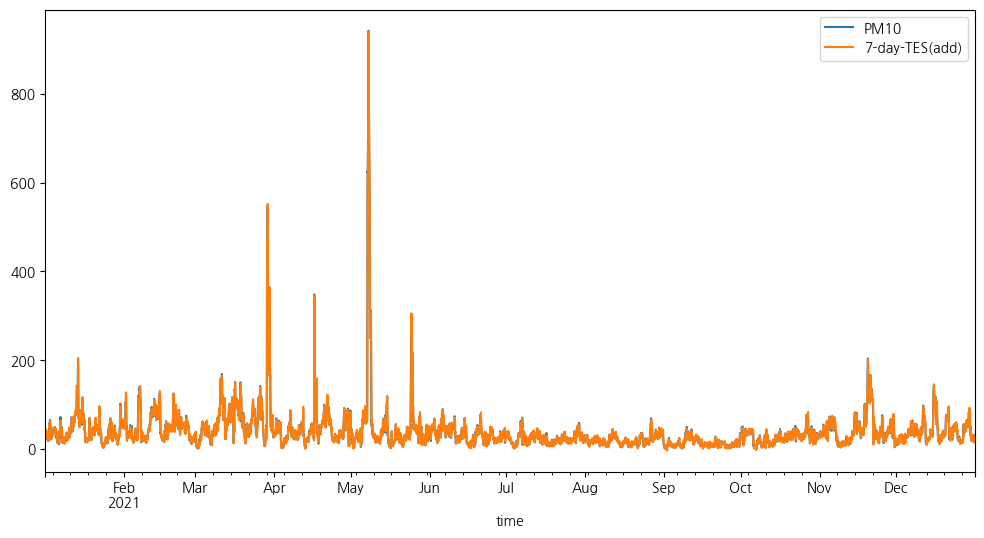

In [39]:
pm10_2021_df[['PM10', '7-day-TES(add)']].plot(figsize=(12,6)).autoscale(axis='x',tight=True);

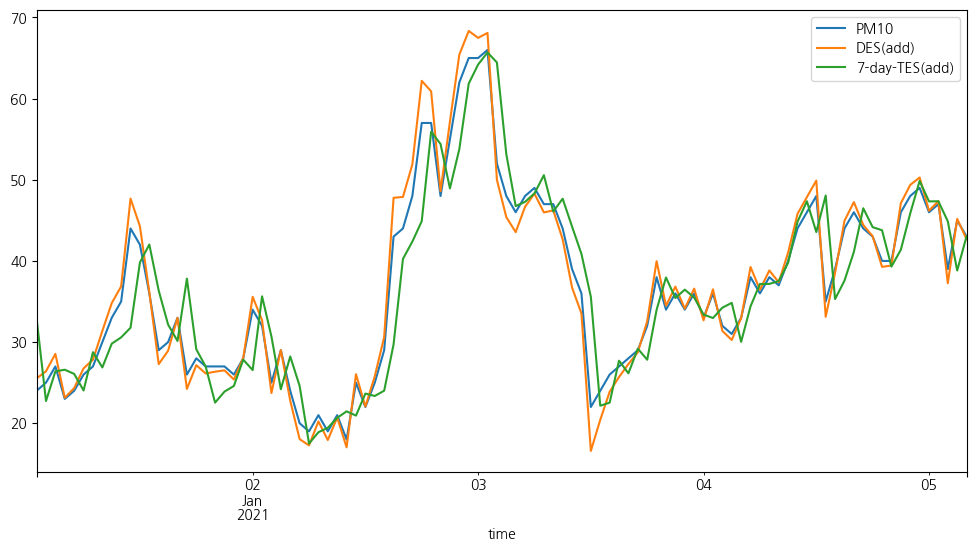

In [40]:
pm10_2021_df[['PM10', 'DES(add)', '7-day-TES(add)']].iloc[:100].plot(figsize=(12,6)).autoscale(axis='x',tight=True);

In [41]:
len(df_22)

2160

In [42]:
2160 / 24

90.0

In [53]:
model = ExponentialSmoothing(pm10_2021_df['PM10'],trend='add',seasonal='add',seasonal_periods=24*7).fit()

forecast_3 = model.forecast(steps=6) # steps시간 만큼 예측
forecast_3

,0
2022-01-01 00:00:00,17.944744
2022-01-01 01:00:00,19.068758
2022-01-01 02:00:00,17.597203
2022-01-01 03:00:00,16.855459
2022-01-01 04:00:00,16.298243
2022-01-01 05:00:00,17.297458


In [54]:
df_22['PM10'].head(6)

,PM10
time,
2022-01-01 00:00:00,20.0
2022-01-01 01:00:00,23.0
2022-01-01 02:00:00,20.0
2022-01-01 03:00:00,20.0
2022-01-01 04:00:00,19.0
2022-01-01 05:00:00,24.0


In [55]:
print(np.sqrt(mse(forecast_3.values, df_22['PM10'].head(6).values)))

3.8202065635844176


In [56]:
r2_score(df_22['PM10'].head(6).values, forecast_3.values)

-3.3781934565360396

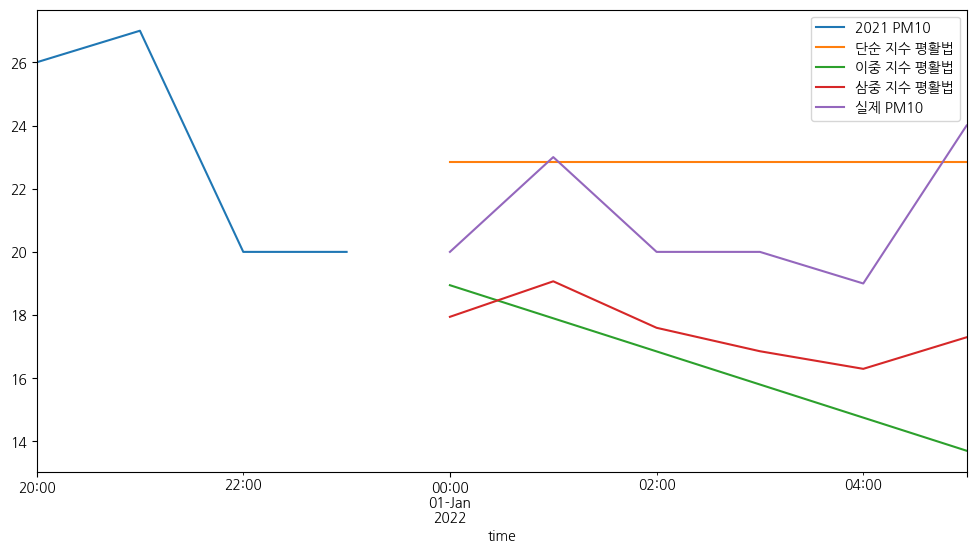

In [46]:
df_21['PM10'][-4:].plot(legend=True,label='2021 PM10', figsize=(12,6))
forecast_1.plot(legend=True,label='단순 지수 평활법')
forecast_2.plot(legend=True,label='이중 지수 평활법')
forecast_3.plot(legend=True,label='삼중 지수 평활법')
df_22['PM10'].head(6).plot(legend=True,label='실제 PM10')
plt.show()

## 3-7. ACF

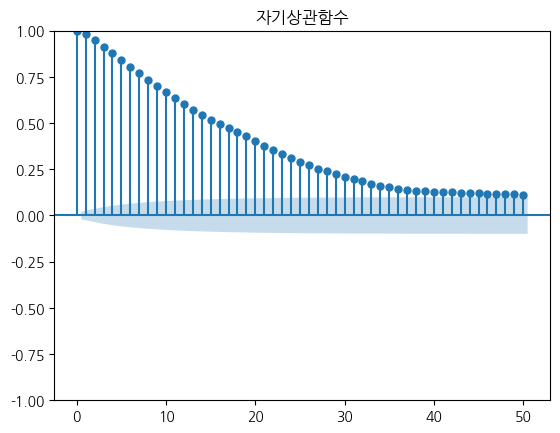

In [ ]:
title = '자기상관함수'
lags = 50
plot_acf(pm10_2021_df['PM10'], title=title, lags=lags);

## 3-8. PACF

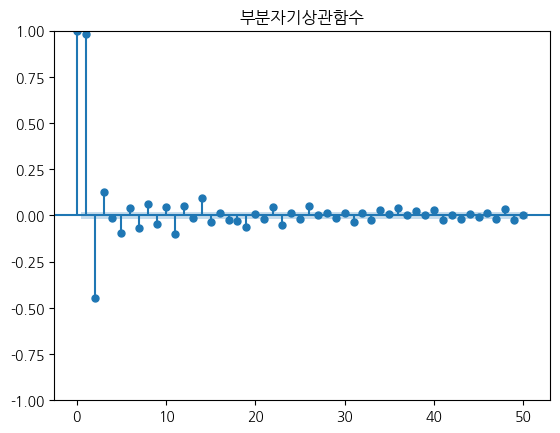

In [ ]:
title = '부분자기상관함수'
lags = 50
plot_pacf(pm10_2021_df['PM10'], title=title, lags=lags);

## 3-9. AR

In [ ]:
AR_model = AutoReg(pm10_2021_df['PM10'], lags=2) # AR(2) 모델.
AR1fit = AR_model.fit()
print(f'Lag: {AR1fit.ar_lags}')
print(f'Coefficients:\n{AR1fit.params}')

Lag: [1, 2]
Coefficients:
const      1.005136
PM10.L1    1.421085
PM10.L2   -0.447006
dtype: float64


In [ ]:
len(pm10_2021_df['PM10'])

8759

In [ ]:
len(df_22['PM10'])

2160

In [ ]:
start=len(pm10_2021_df['PM10']) # 8759
end=len(pm10_2021_df['PM10']) + 5
pred = AR1fit.predict(start=start, end=end, dynamic=False).rename('AR(2) Pred')

In [ ]:
pred

,AR(2) Pred
2022-01-01 00:00:00,20.486704
2022-01-01 01:00:00,21.178351
2022-01-01 02:00:00,21.943680
2022-01-01 03:00:00,22.722108
2022-01-01 04:00:00,23.486212
2022-01-01 05:00:00,24.224107


In [ ]:
df_22['PM10'].head(6)

,PM10
time,
2022-01-01 00:00:00,20.0
2022-01-01 01:00:00,23.0
2022-01-01 02:00:00,20.0
2022-01-01 03:00:00,20.0
2022-01-01 04:00:00,19.0
2022-01-01 05:00:00,24.0


In [ ]:
print(np.sqrt(mse(df_22['PM10'].head(6).values, pred.values)))

2.412445936342504


In [ ]:
r2_score(df_22['PM10'].head(6).values, pred.values)

-0.7459686187326384

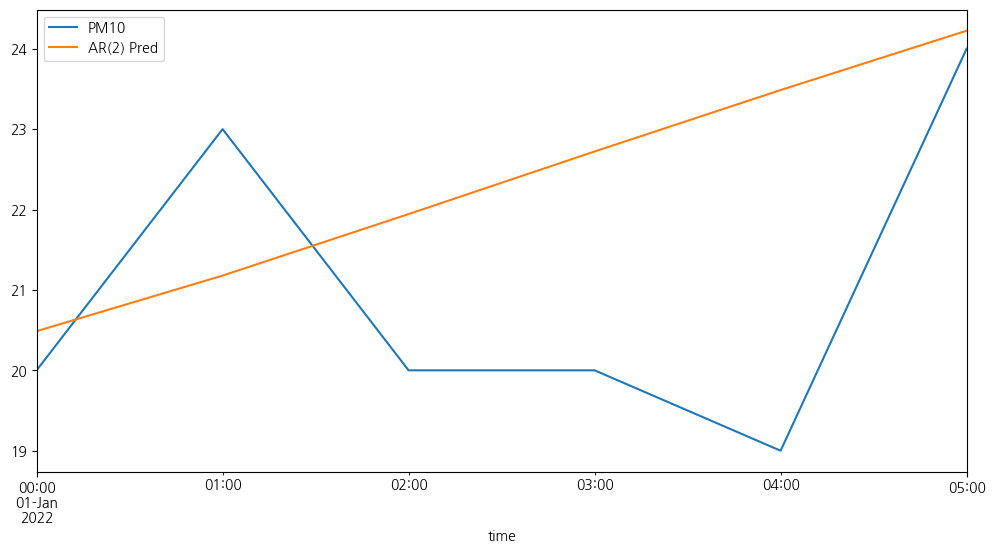

In [ ]:
df_22['PM10'][:6].plot(legend=True)
pred.plot(legend=True,figsize=(12,6));

# 데이터에 추세가 있으면 AR만으로는 모델링이 안됨 → 차분 필요
# AR은 주기적인 패턴을 반영하지 못함.
# lags를 크게할 수록 그래프가 조금씩 복잡해지지만 결과는 여전히 좋지 못함.

## 3-10. ARIMA

In [ ]:
adf_test(df_21['PM10'])  # 추세는 없음. 아까 위에서 7일, 28일, ... 이라는 주기는 확인 했음.

Augmented Dickey-Fuller Test: 
ADF test statistic     -1.001077e+01
p-value                 1.781192e-17
# lags used             3.700000e+01
# observations          8.721000e+03
critical value (1%)    -3.431100e+00
critical value (5%)    -2.861871e+00
critical value (10%)   -2.566946e+00
Strong evidence against the null hypothesis
Reject the null hypothesis
Data has no unit root and is stationary


In [ ]:
#auto_arima(df_21['PM10'],seasonal=False, trace=True).summary() # ARMA모델이므로 seasonal=False라고 뒀음

In [ ]:
ARIMA_model = ARIMA(df_21['PM10'], order=(4, 1, 1)) # auto_arima()로 구한 best 모델
ARIMA_results = ARIMA_model.fit()
ARIMA_results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                   PM10   No. Observations:                 8759
Model:                 ARIMA(4, 1, 1)   Log Likelihood              -30362.782
Date:                Thu, 01 May 2025   AIC                          60737.565
Time:                        13:42:37   BIC                          60780.031
Sample:                    01-01-2021   HQIC                         60752.035
                         - 12-31-2021                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.4387      0.002   -175.646      0.000      -0.444      -0.434
ar.L2          0.3294      0.002    144.457      0.000       0.325       0.334
ar.L3         -0.1708      0.003    -67.364      0.000      -0.176      -0.166
ar.L4          0.0599      0.003     19.132      0.000       0.054       0.066
ma.L1          0.9899      0.001    706.289      0.000       0.987       0.993
sigma2        60.0770      0.158    381.019      0.000      59.768      60.386
===================================================================================
Ljung-Box (L1) (Q):                   0.01   Jarque-Bera (JB):           5530616.50
Prob(Q):                              0.93   Prob(JB):                         0.00
Heteroskedasticity (H):               0.24   Skew:                            -0.23
Prob(H) (two-sided):                  0.00   Kurtosis:                       126.11
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

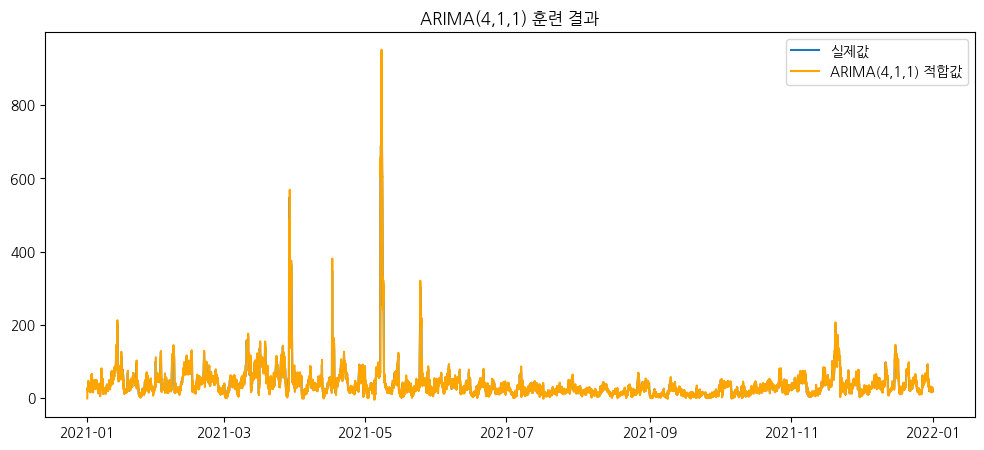

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(df_21['PM10'], label='실제값')
plt.plot(ARIMA_results.fittedvalues, label='ARIMA(4,1,1) 적합값', color='orange')
plt.legend()
plt.title("ARIMA(4,1,1) 훈련 결과")
plt.show()

In [ ]:
forecast = ARIMA_results.forecast(steps=6)
print("예측값:\n", forecast)

예측값:
 2022-01-01 00:00:00    19.203599
2022-01-01 01:00:00    20.808605
2022-01-01 02:00:00    19.423007
2022-01-01 03:00:00    20.695628
2022-01-01 04:00:00    19.359035
2022-01-01 05:00:00    20.697413
Freq: h, Name: predicted_mean, dtype: float64


In [ ]:
forecast

,predicted_mean
2022-01-01 00:00:00,19.203599
2022-01-01 01:00:00,20.808605
2022-01-01 02:00:00,19.423007
2022-01-01 03:00:00,20.695628
2022-01-01 04:00:00,19.359035
2022-01-01 05:00:00,20.697413


In [ ]:
print(np.sqrt(mse(df_22['PM10'].head(6).values, forecast.values)))

1.6975115060876396


In [ ]:
r2_score(df_22['PM10'].head(6).values, forecast.values)

0.13553640601002215

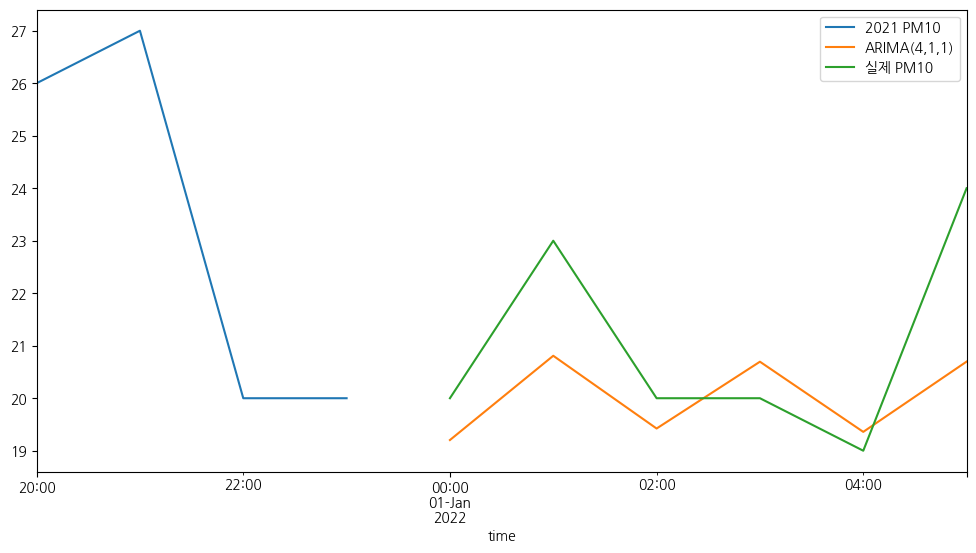

In [ ]:
df_21['PM10'][-4:].plot(legend=True,label='2021 PM10', figsize=(12,6))
forecast.plot(legend=True,label='ARIMA(4,1,1)')
df_22['PM10'].head(6).plot(legend=True,label='실제 PM10')
plt.show()

In [ ]:
start=len(pm10_2021_df['PM10']) # 8759
end=len(pm10_2021_df['PM10']) + 23

predictions = ARIMA_results.predict(start=start, end=end, dynamic=False, typ='levels').rename('ARIMA(4, 1, 1) Predictions')

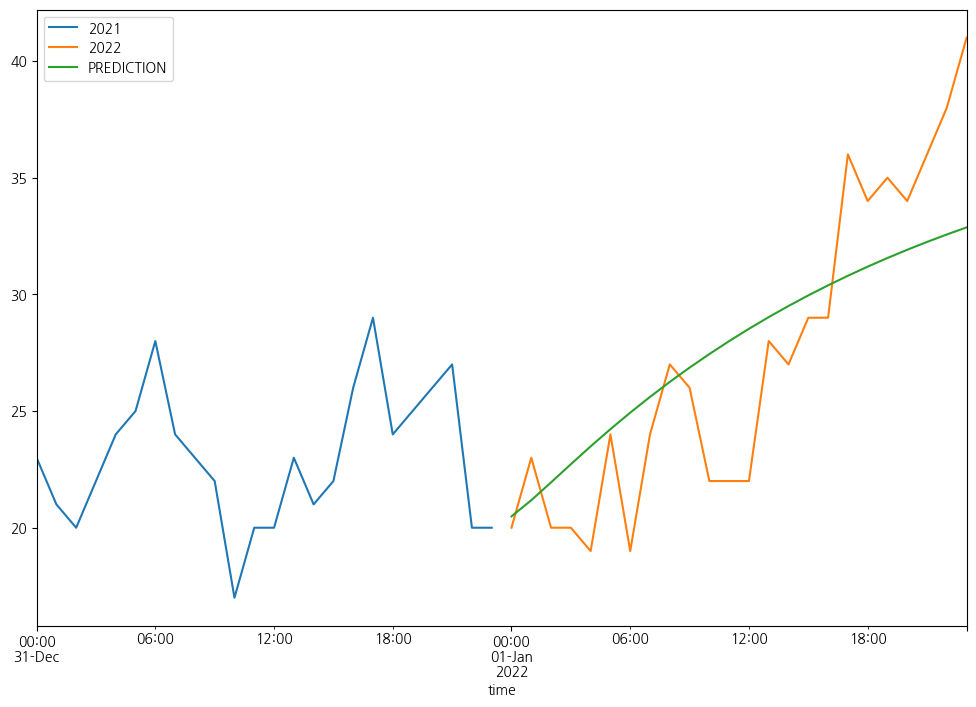

In [ ]:
df_21['PM10'][-24:].plot(legend=True,label='2021')
df_22['PM10'][:24].plot(legend=True,label='2022',figsize=(12,8))
pred[:24].plot(legend=True,label='PREDICTION');

## 3-11. SARIMA

In [ ]:
model = auto_arima(df_21['PM10'],
                   seasonal=True,
                   m=24,  # 하루 단위 계절성
                   start_p=0, start_q=0,
                   max_p=2, max_q=2,
                   start_P=0, start_Q=0,
                   max_P=1, max_Q=1,
                   d=None,  # 자동 결정
                   D=1,     # 고정
                   trace=True,
                   error_action='ignore',
                   suppress_warnings=True,
                   stepwise=True)

Performing stepwise search to minimize aic
 ARIMA(0,0,0)(0,1,0)[24] intercept   : AIC=94962.064, Time=4.07 sec


KeyboardInterrupt: 

In [ ]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

SARIMA_model = SARIMAX(df_21['PM10'],
                order=(1, 1, 1),
                seasonal_order=(2, 0, 0, 168),
                enforce_stationarity=False,
                enforce_invertibility=False)

fit = SARIMA_model.fit()
fit.summary()

KeyboardInterrupt: 